# Car Price Prediction with K-Nearest Neighbors

**Objective:** Prepare automotive features and compare KNN regression models for car price prediction.

**Dataset used:** `data/imports-85.data`

**Main techniques used:** Data cleaning, missing value handling, normalization, KNN regression, model comparison


In [1]:
import pandas as pd
import numpy as np 
pd.options.display.max_columns = 99
cols= ['symboling', 'normalized-losses', 'make' , 'fuel-type' , 'aspiration','num-of-doors',
       'body-style','drive-wheels' ,'engine-location','wheel-base' , 'length' , 'width',
       'height' , 'curb-weight' , 'engine-type' , 'num-of-cylinders' , 'engine-size',
       'fuel-system' , 'bore' , 'stroke' , 'compression-rate' , 'horsepower', 'peak-rpm',
       'city-mpg' , 'highway-mpg' , 'price' ]
cars = pd.read_csv('data/imports-85.data', names=cols)
cars.head()  


In [53]:
numeric_cars = numeric_cars.replace('?', np.nan)
numeric_cars.head()


,normalized-losses,wheel-base,length,width,height,curb-weight,bore,stroke,compression-rate,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,NaN,88.6,168.8,64.1,48.8,2548,3.47,2.68,9.0,111,5000,21,27,13495
1,NaN,88.6,168.8,64.1,48.8,2548,3.47,2.68,9.0,111,5000,21,27,16500
2,NaN,94.5,171.2,65.5,52.4,2823,2.68,3.47,9.0,154,5000,19,26,16500
3,164,99.8,176.6,66.2,54.3,2337,3.19,3.40,10.0,102,5500,24,30,13950
4,164,99.4,176.6,66.4,54.3,2824,3.19,3.40,8.0,115,5500,18,22,17450


In [59]:
#selection des colonnes numériques et continues a partir de la documentation 
#j'ai changer normlized woth symboling to connvert to float aftet that 
continuous_values_cols = ['normalized-losses', 'wheel-base' , 'length','width',
                    'height' , 'curb-weight' , 'bore' , 'stroke' , 'compression-rate',
                    'horsepower' , 'peak-rpm', 'city-mpg' , 'highway-mpg' , 'price' ]
numeric_cars = cars[continuous_values_cols]
numeric_cars = numeric_cars.replace('?', np.nan)
numeric_cars.head()


,normalized-losses,wheel-base,length,width,height,curb-weight,bore,stroke,compression-rate,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,NaN,88.6,168.8,64.1,48.8,2548,3.47,2.68,9.0,111,5000,21,27,13495
1,NaN,88.6,168.8,64.1,48.8,2548,3.47,2.68,9.0,111,5000,21,27,16500
2,NaN,94.5,171.2,65.5,52.4,2823,2.68,3.47,9.0,154,5000,19,26,16500
3,164,99.8,176.6,66.2,54.3,2337,3.19,3.40,10.0,102,5500,24,30,13950
4,164,99.4,176.6,66.4,54.3,2824,3.19,3.40,8.0,115,5500,18,22,17450


In [61]:
numeric_cars = numeric_cars.astype('float')
numeric_cars.isnull().sum()


normalized-losses    41
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
bore                  4
stroke                4
compression-rate      0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64

In [63]:
numeric_cars = numeric_cars.dropna(subset= ['price']) #dropna ssupprime les ligne qui contient des valeur de prix manquante
numeric_cars.isnull().sum()


normalized-losses    37
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
bore                  4
stroke                4
compression-rate      0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [65]:
#remplaver les valeurs manquantes dans les autres colonnes en utilisant la moyenne
numeric_cars = numeric_cars.fillna(numeric_cars.mean())



In [67]:
numeric_cars.isnull().sum()


normalized-losses    0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
bore                 0
stroke               0
compression-rate     0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [69]:
#normaliser toutes les colonnes  de sorte que les valeurs soient comprises entre 0 et 1 en utilisant la moyenne 
#sauf pour les colonne cible 'price'
price_col = numeric_cars['price']
numeric_cars = (numeric_cars - numeric_cars.min())/(numeric_cars.max() - numeric_cars.min())
numeric_cars['price'] = price_col
numeric_cars.head()


,normalized-losses,wheel-base,length,width,height,curb-weight,bore,stroke,compression-rate,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,0.298429,0.058309,0.413433,0.324786,0.083333,0.411171,0.664286,0.290476,0.1250,0.294393,0.346939,0.222222,0.289474,13495.0
1,0.298429,0.058309,0.413433,0.324786,0.083333,0.411171,0.664286,0.290476,0.1250,0.294393,0.346939,0.222222,0.289474,16500.0
2,0.298429,0.230321,0.449254,0.444444,0.383333,0.517843,0.100000,0.666667,0.1250,0.495327,0.346939,0.166667,0.263158,16500.0
3,0.518325,0.384840,0.529851,0.504274,0.541667,0.329325,0.464286,0.633333,0.1875,0.252336,0.551020,0.305556,0.368421,13950.0
4,0.518325,0.373178,0.529851,0.521368,0.541667,0.518231,0.464286,0.633333,0.0625,0.313084,0.551020,0.138889,0.157895,17450.0


In [85]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

def knn_train_test(train_col, target_col, df):
    knn= KNeighborsRegressor()
    np.random.seed(0)
    #randomiser l'ordre des lignes du dataframe
    shuffled_index = np.random.permutation(df.index)
    rand_df = df.reindex(shuffled_index)
    #diviser le nombre de ligne de moitié
    last_train_row = int(len(rand_df) / 2)
    #selectionner le permier moitie en set de training
    #selection la deuxieme moitie en set de test 
    train_df = rand_df.iloc[0:last_train_row]
    test_df = rand_df.iloc[last_train_row:]
    #ajuster un modele knn en utilisant la valeur par defaut k 
    knn.fit(train_df[[train_col]], train_df[target_col])
    #faire des prediction en utilisant ce modele
    predicted_labels = knn.predict(test_df[[train_col]])
    #calculer et retourner la valeur rmse 
    mse = mean_squared_error(test_df[target_col],predicted_labels)
    rmse = np.sqrt(mse)
    return rmse


In [89]:
rmse_results = {}
train_cols = numeric_cars.columns.drop('price')
#pour chaque colonne (excepte 'price')entrainer un modele et retourner la valeur rmse .
#et a jouter cette valeur au dictionnaire 'rmse_results'.
for col in train_cols: 
    rmse_val = knn_train_test(col, 'price', numeric_cars)
    rmse_results[col] = rmse_val
#creer un objets series depuis le dictionnaire 
#ainsi nous poouvons facilment voir les resultats, les trier etxc etc 
rmse_results_series = pd.Series(rmse_results)
rmse_results_series.sort_values()


curb-weight          3782.517763
highway-mpg          3825.547853
width                4067.565225
city-mpg             4998.578075
horsepower           5015.709416
length               5722.180847
compression-rate     6038.443497
wheel-base           6212.244807
bore                 6375.811122
peak-rpm             6794.853225
normalized-losses    6924.767940
stroke               7142.509829
height               7502.274571
dtype: float64

In [163]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

def knn_train_test2(train_col, target_col, df):
    np.random.seed(0)

    # Mélanger les lignes
    shuffled_index = np.random.permutation(df.index)
    rand_df = df.reindex(shuffled_index)

    # Diviser 50% entraînement / 50% test
    last_train_row = int(len(rand_df) / 2)
    train_df = rand_df.iloc[0:last_train_row]
    test_df = rand_df.iloc[last_train_row:]

    # Tester différentes valeurs de k
    k_values = [1, 3, 5, 7, 9]
    k_rmses = {}

    for k in k_values: 
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(train_df[[train_col]], train_df[target_col])
        predicted_labels = knn.predict(test_df[[train_col]])
        mse = mean_squared_error(test_df[target_col], predicted_labels)
        rmse = np.sqrt(mse)
        k_rmses[k] = rmse

    return k_rmses


In [165]:

# Appliquer à toutes les colonnes sauf 'price'
feature_k_rmse_results = {}
train_cols = numeric_cars.columns.drop('price')

for col in train_cols:
    rmse_val = knn_train_test2(col, 'price', numeric_cars)
    feature_k_rmse_results[col] = rmse_val

# Affichage des résultats
for feature, k_rmse in feature_k_rmse_results.items():
    print(f"\nColonne : {feature}")
    for k, rmse in k_rmse.items():
        print(f"  k={k} → RMSE = {rmse:.2f}")



Colonne : normalized-losses
  k=1 → RMSE = 6057.53
  k=3 → RMSE = 6596.10
  k=5 → RMSE = 6924.77
  k=7 → RMSE = 7120.23
  k=9 → RMSE = 7348.92

Colonne : wheel-base
  k=1 → RMSE = 6489.45
  k=3 → RMSE = 7421.61
  k=5 → RMSE = 6212.24
  k=7 → RMSE = 5535.77
  k=9 → RMSE = 5371.94

Colonne : length
  k=1 → RMSE = 5363.79
  k=3 → RMSE = 5439.63
  k=5 → RMSE = 5722.18
  k=7 → RMSE = 5505.06
  k=9 → RMSE = 5374.87

Colonne : width
  k=1 → RMSE = 5024.17
  k=3 → RMSE = 4016.11
  k=5 → RMSE = 4067.57
  k=7 → RMSE = 3936.46
  k=9 → RMSE = 3901.11

Colonne : height
  k=1 → RMSE = 9700.94
  k=3 → RMSE = 7730.83
  k=5 → RMSE = 7502.27
  k=7 → RMSE = 7222.74
  k=9 → RMSE = 7315.27

Colonne : curb-weight
  k=1 → RMSE = 5939.55
  k=3 → RMSE = 4283.68
  k=5 → RMSE = 3782.52
  k=7 → RMSE = 3714.99
  k=9 → RMSE = 4083.49

Colonne : bore
  k=1 → RMSE = 6081.76
  k=3 → RMSE = 6163.48
  k=5 → RMSE = 6375.81
  k=7 → RMSE = 6536.50
  k=9 → RMSE = 6380.25

Colonne : stroke
  k=1 → RMSE = 7352.98
  k=3 → RMS

normalized-losses
average_rmse : 6809.507591113807
wheel-base
average_rmse : 6206.19974719281
length
average_rmse : 5481.105004837487
width
average_rmse : 4189.083887950638
height
average_rmse : 7894.412734463598
curb-weight
average_rmse : 4360.845871048696
bore
average_rmse : 6307.560836454496
stroke
average_rmse : 7105.977198596486
compression-rate
average_rmse : 6628.768853554623
horsepower
average_rmse : 4907.446259811364
peak-rpm
average_rmse : 7051.92722210883
city-mpg
average_rmse : 4638.434400354712
highway-mpg
average_rmse : 4170.291993746854


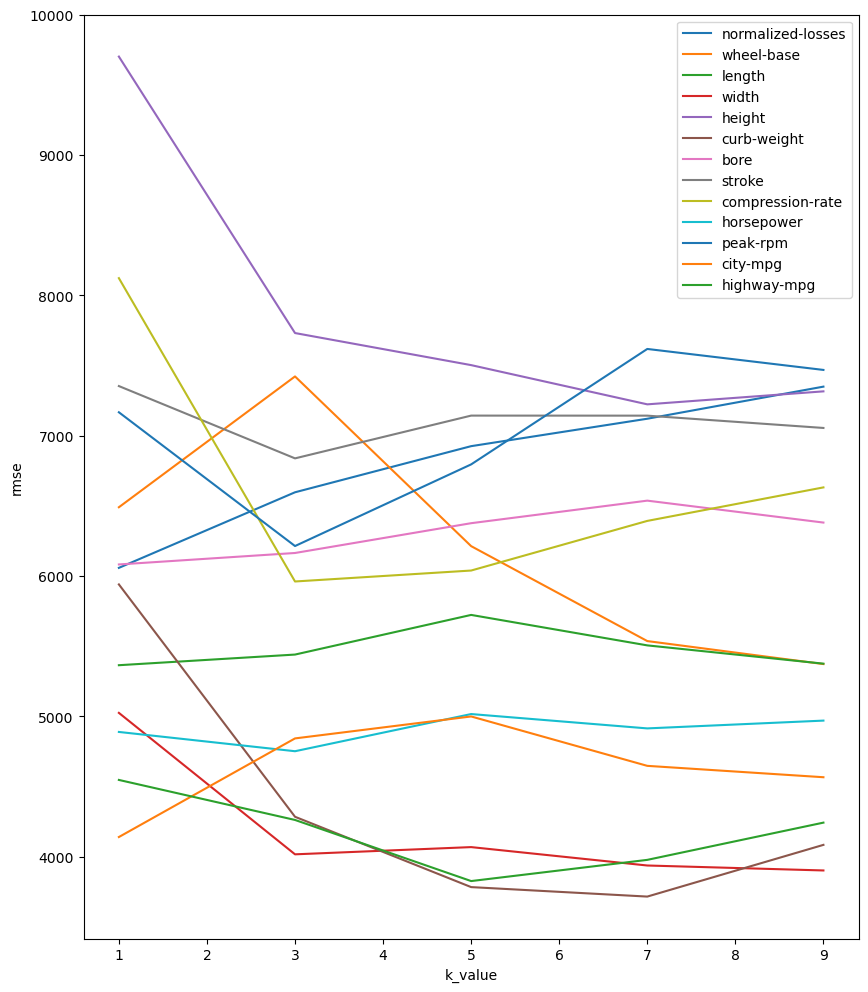

In [167]:
import matplotlib.pyplot as plt 
%matplotlib inline
best_features = {}
plt.figure(figsize=(10,12))
for key , value in feature_k_rmse_results.items():
    x = list(value.keys())
    y = list(value.values())
    order = np.argsort(x)
    x_ordered = np.array(x)[order]
    y_ordered = np.array(y)[order]
    print(key)
    print('average_rmse : '+str(np.mean(y)))
    best_features[key] =np.mean(y)
    plt.plot(x_ordered, y_ordered , label=key)
    plt.xlabel("k_value")
    plt.ylabel("rmse")
plt.legend()
plt.show()


In [169]:
sorted_features_list = sorted(best_features , key=best_features.get)
sorted_features_list 


['highway-mpg',
 'width',
 'curb-weight',
 'city-mpg',
 'horsepower',
 'length',
 'wheel-base',
 'bore',
 'compression-rate',
 'normalized-losses',
 'peak-rpm',
 'stroke',
 'height']

In [171]:
print(numeric_cars)


     normalized-losses  wheel-base    length     width    height  curb-weight  \
0             0.298429    0.058309  0.413433  0.324786  0.083333     0.411171   
1             0.298429    0.058309  0.413433  0.324786  0.083333     0.411171   
2             0.298429    0.230321  0.449254  0.444444  0.383333     0.517843   
3             0.518325    0.384840  0.529851  0.504274  0.541667     0.329325   
4             0.518325    0.373178  0.529851  0.521368  0.541667     0.518231   
..                 ...         ...       ...       ...       ...          ...   
200           0.157068    0.655977  0.711940  0.735043  0.641667     0.567882   
201           0.157068    0.655977  0.711940  0.726496  0.641667     0.605508   
202           0.157068    0.655977  0.711940  0.735043  0.641667     0.591156   
203           0.157068    0.655977  0.711940  0.735043  0.641667     0.670675   
204           0.157068    0.655977  0.711940  0.735043  0.641667     0.610551   

         bore    stroke  co

In [173]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Fonction KNN avec plusieurs variables (multivariée)
def knn_train_test3(train_cols, target_col, df):
    np.random.seed(0)

    # Mélanger les lignes
    shuffled_index = np.random.permutation(df.index)
    rand_df = df.reindex(shuffled_index)

    # 50% training / 50% test
    last_train_row = int(len(rand_df) / 2)
    train_df = rand_df.iloc[0:last_train_row]
    test_df = rand_df.iloc[last_train_row:]

    # valeur fixe de k
    k = 5
    knn = KNeighborsRegressor(n_neighbors=k)

    # Entraînement avec plusieurs colonnes
    knn.fit(train_df[train_cols], train_df[target_col])

    # Prédiction
    predicted_labels = knn.predict(test_df[train_cols])

    # Calcul de RMSE
    mse = mean_squared_error(test_df[target_col], predicted_labels)
    rmse = np.sqrt(mse)

    return rmse


In [175]:
k_rmse_features = {}

best_two_features = sorted_features_list[0:2]
best_three_features = sorted_features_list[0:3]
best_four_features = sorted_features_list[0:4]
best_five_features = sorted_features_list[0:5]
best_six_features = sorted_features_list[0:6]

k_rmse_features["best_two_rmse"] = knn_train_test3(best_two_features, 'price', numeric_cars)
k_rmse_features["best_three_rmse"] = knn_train_test3(best_three_features, 'price', numeric_cars)
k_rmse_features["best_four_rmse"] = knn_train_test3(best_four_features, 'price', numeric_cars)
k_rmse_features["best_five_rmse"] = knn_train_test3(best_five_features, 'price', numeric_cars)
k_rmse_features["best_six_rmse"] = knn_train_test3(best_six_features, 'price', numeric_cars)

# Affichage des résultats
for name, rmse in k_rmse_features.items():
    print(f"{name} → RMSE = {rmse:.2f}")


best_two_rmse → RMSE = 3943.28
best_three_rmse → RMSE = 3495.62
best_four_rmse → RMSE = 3499.79
best_five_rmse → RMSE = 3486.56
best_six_rmse → RMSE = 3589.57


In [141]:
#validation croisee: 
from sklearn.model_selection import KFold

def knn_cross_val(train_col, target_col, df, k=5):
    knn = KNeighborsRegressor()
    kf = KFold(n_splits=k, shuffle=True, random_state=1)
    
    rmse_values = []

    for train_index, test_index in kf.split(df):
        train_df = df.iloc[train_index]
        test_df = df.iloc[test_index]

        # Entraîner le modèle sur la colonne choisie
        knn.fit(train_df[[train_col]], train_df[target_col])

        # Prédire
        predicted = knn.predict(test_df[[train_col]])

        # Calcul de la RMSE
        mse = mean_squared_error(test_df[target_col], predicted)
        rmse = np.sqrt(mse)
        rmse_values.append(rmse)

    # Retourner la RMSE moyenne sur les k folds
    return np.mean(rmse_values)


In [193]:
def knn_train_test4(train_col, target_col, df):
    np.random.seed(0)

    # Mélanger les lignes
    shuffled_index = np.random.permutation(df.index)
    rand_df = df.reindex(shuffled_index)

    # Diviser 50% entraînement / 50% test
    last_train_row = int(len(rand_df) / 2)
    train_df = rand_df.iloc[0:last_train_row]
    test_df = rand_df.iloc[last_train_row:]

    # Tester différentes valeurs de k
    k_values = [i for i in range(1,25)]
    k_rmses = {}

    for k in k_values: 
        #on ajuste le modele en utiliant la valeur k .
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(train_df[train_col], train_df[target_col])
        #faire des predictions en utilsant le moddéle 
        predicted_labels = knn.predict(test_df[train_col])
        #calculer et retourner 
        mse = mean_squared_error(test_df[target_col], predicted_labels)
        rmse = np.sqrt(mse)
        k_rmses[k] = rmse

    return k_rmses


In [197]:
features= [best_three_features , best_four_features , best_five_features ]
k_rmse_results = {}

k_rmse_results["best_three_features"] = knn_train_test4(best_three_features, 'price', numeric_cars)
k_rmse_results["best_four_features"] = knn_train_test4(best_four_features, 'price', numeric_cars)
k_rmse_results["best_five_features"] = knn_train_test4(best_five_features, 'price', numeric_cars)

k_rmse_results


{'best_three_features': {1: 4394.548881431077,
  2: 4012.0099191781865,
  3: 3701.833701947683,
  4: 3363.910603949128,
  5: 3495.623297555937,
  6: 3598.949475473044,
  7: 3537.3016311966785,
  8: 3676.7657541501185,
  9: 3743.2253449247723,
  10: 3879.513773325949,
  11: 4072.203631742671,
  12: 4152.793042259954,
  13: 4213.071707271992,
  14: 4172.301649643432,
  15: 4222.848680728453,
  16: 4213.672852924302,
  17: 4217.708194667094,
  18: 4192.358069141822,
  19: 4216.682906853658,
  20: 4294.600926122643,
  21: 4341.440754567459,
  22: 4376.278394074132,
  23: 4397.879066167476,
  24: 4392.677964811508},
 'best_four_features': {1: 3306.221745092542,
  2: 3284.6545390031597,
  3: 3328.96189975689,
  4: 3405.3968098519013,
  5: 3499.789211530962,
  6: 3602.800208811121,
  7: 3599.006775775112,
  8: 3834.832073207766,
  9: 3883.5154162990257,
  10: 3961.5985436924498,
  11: 4015.5471797566574,
  12: 4059.138355727462,
  13: 4089.1784112140704,
  14: 4130.664116157744,
  15: 4095.22

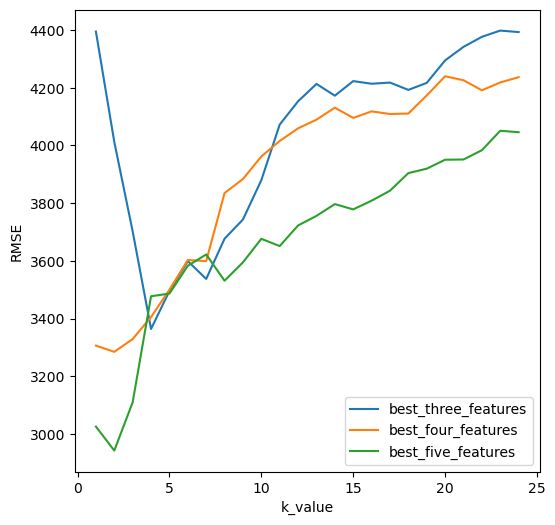

In [205]:
plt.figure(figsize=(6,6))
for key , value in k_rmse_results.items():
     x = list(value.keys())
     y = list(value.values())
     plt.plot(x , y,label=key)
     plt.xlabel("k_value")
     plt.ylabel("RMSE")

plt.legend()
plt.show()


## Conclusion

**What was done:** Cleaned the automotive dataset and compared KNN regression performance across features and neighbor values.

**What was learned:** Distance-based models are sensitive to missing values, scaling, and feature choice.

**Possible improvements:** Use systematic hyperparameter tuning and test additional distance metrics or feature subsets.
